# BIL545 · Güncel Bölüm 2

Hakan’ın b4c394a sürümündeki veri hazırlamasına uyarlanmıştır. Bölüm 1’in 39 kod hücresi önceki doğrulanmış sürümle aynıdır. Analiz kodları ve kayıtlı sonuçlar Colab’da doğrulanmış nihai dosyadan aynen alınmıştır. Ayrı dosyanın hazırlık hücreleri önceki yerel testte doğrulanan hazırlıktır.

bank-full.csv dosyasını aynı klasöre koyup tümünü sırayla çalıştırın. Üretilen uretilen/ klasörünü Bölüm 3 için saklayın.


In [ ]:
# Bölüm 2–3 çalışma ortamı; Bölüm 1 üzerinde değişiklik yapmaz.
import os, shutil, sys, subprocess, importlib.metadata
# Paketler import edilmeden önce doğrulanmış sürümler hazırlanır.
gerekli={"numpy":"2.4.6","pandas":"2.2.3","scipy":"1.16.3","scikit-learn":"1.6.1","matplotlib":"3.10.0","mlxtend":"0.23.4"}
eksik=[]
for paket,surum in gerekli.items():
    try: uygun=importlib.metadata.version(paket)==surum
    except importlib.metadata.PackageNotFoundError: uygun=False
    if not uygun: eksik.append(paket+"=="+surum)
if eksik: subprocess.check_call([sys.executable,"-m","pip","install",*eksik])
try:
    import certifi
    os.environ["SSL_CERT_FILE"]=certifi.where()
except ImportError: pass
os.environ["JAVA_TOOL_OPTIONS"]=(os.environ.get("JAVA_TOOL_OPTIONS","")+" -Duser.language=en -Duser.country=US").strip()
from pathlib import Path
from IPython.display import display, Markdown
JAVA=shutil.which("java")
yerel_java=Path("/Applications/weka-3.8.7.app/Contents/runtime/Contents/Home/bin/java")
if yerel_java.exists(): JAVA=str(yerel_java)
if JAVA is None: raise RuntimeError("Java 17+ gerekli.")
Path("uretilen").mkdir(exist_ok=True)


In [ ]:
import sys
# python sürümü icin
import random
import numpy as np
import pandas as pd
import sklearn
import scipy
# gerekli kütüphaneleri ekliyorum
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("SciPy:", scipy.__version__)
print("Random seed:", SEED)

Python: 3.13.18
NumPy: 2.4.6
Pandas: 2.2.3
Scikit-learn: 1.6.1
SciPy: 1.16.3
Random seed: 42


In [ ]:
from pathlib import Path


# Veri dosyasının konumu
dosya_yolu = Path("bank-full.csv")

# Dosya bulunmuyorsa kullanıcıdan yüklemesini iste
if not dosya_yolu.exists():
    print("Lütfen bank-full.csv dosyasını yükleyin.")
    try:
        from google.colab import files
        files.upload()
    except ImportError as exc:
        raise FileNotFoundError("bank-full.csv dosyasini notebook ile ayni klasore koyun.") from exc

# Dosyanın varlığını kontrol et
if not dosya_yolu.exists():
    raise FileNotFoundError("bank-full.csv bulunamadı.")

# Veri kümesini oku
df = pd.read_csv(dosya_yolu, sep=";")

# Temel bilgileri göster
print("Satır sayısı:", df.shape[0])
print("Sütun sayısı:", df.shape[1])
print("Sütunlar:", df.columns.tolist())

display(df.head())

Satır sayısı: 45211
Sütun sayısı: 17
Sütunlar: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [ ]:
from pathlib import Path
import hashlib
import pandas as pd
# from patlib:dosya yol kontrolü yapmak için
# import hashlib:hash hesaplayıp kontrol etmek için ekledim
# import pandas :veri seti okumak ve işlem yapmak için

# İlk veri yükleme hücresinde kullanılan dosya
ham_dosya = dosya_yolu

assert ham_dosya.is_file(), (
    "bank-full.csv bulunamadı. "
    "Önce veri dosyasını Colab'a yükleyin."
)

# Ham veri üzerinde bağımsız bütünlük kontrolü
ham_kontrol = pd.read_csv(ham_dosya, sep=";")

beklenen_sutunlar = [
    "age", "job", "marital", "education",
    "default", "balance", "housing", "loan",
    "contact", "day", "month", "duration",
    "campaign", "pdays", "previous",
    "poutcome", "y"
]
# veri seti sütünları belirledim alttada kontrol ediyorum

assert ham_kontrol.shape == (45211, 17)
assert ham_kontrol.columns.tolist() == beklenen_sutunlar
assert (ham_kontrol["y"] == "yes").sum() == 5289
# yes olan kayıt sayısı
with open(ham_dosya, "rb") as f:
    veri_hash = hashlib.file_digest(
        f, "sha256"
    ).hexdigest()
# sha256 hash degeri hesaplama
print("=== HAM VERİ BÜTÜNLÜK KONTROLÜ ===")
print("Dosya:", ham_dosya.name)
print("Boyut:", ham_kontrol.shape)
print(
    "Pozitif hedef sayısı:",
    (ham_kontrol["y"] == "yes").sum()
)
print("SHA-256:", veri_hash)

print("\nHam veri bütünlük kontrolü başarılı.")

beklenen_veri_hash = (
    "d1513ec63b385506f7cfce9f2c5caa9fe99e7ba4e8c3fa264b3aaf0f849ed32d"
)

assert veri_hash == beklenen_veri_hash, (
    "Ham veri dosyasının SHA-256 değeri beklenen değerle eşleşmiyor."
)

print("Ham veri SHA-256 doğrulaması başarılı.")

=== HAM VERİ BÜTÜNLÜK KONTROLÜ ===
Dosya: bank-full.csv
Boyut: (45211, 17)
Pozitif hedef sayısı: 5289
SHA-256: d1513ec63b385506f7cfce9f2c5caa9fe99e7ba4e8c3fa264b3aaf0f849ed32d

Ham veri bütünlük kontrolü başarılı.
Ham veri SHA-256 doğrulaması başarılı.


In [ ]:
# Orijinal veri kümesini koru
df_eksiklik = df.copy()

# Bilinmeyen kategorik değerler
eksik_sutunlar = ["job", "education", "contact"]

for sutun in eksik_sutunlar:
    df_eksiklik[sutun] = df_eksiklik[sutun].replace(
        "unknown", np.nan
    )

# Önceki iletişim gerçekleşmemişse
# önceki kampanya sonucu uygulanabilir değildir
iletisim_yok = df["previous"] == 0

df_eksiklik.loc[
    iletisim_yok, "poutcome"
] = "not_applicable"

# Önceki iletişim var fakat sonuç bilinmiyorsa
# eksik değer olarak işaretle
sonuc_bilinmiyor = (
    (df["previous"] > 0) &
    (df["poutcome"] == "unknown")
)

df_eksiklik.loc[
    sonuc_bilinmiyor, "poutcome"
] = np.nan

# Eksik değerlerin özetini oluştur
eksiklik_ozeti = pd.DataFrame({
    "Eksik sayısı": df_eksiklik.isna().sum(),
    "Eksik oranı (%)": (
        df_eksiklik.isna().mean() * 100
    )
})

eksiklik_ozeti = eksiklik_ozeti.sort_values(
    "Eksik oranı (%)", ascending=False
)

display(eksiklik_ozeti.round(2))

# Orijinal verinin değişmediğini kontrol et
assert df.isna().sum().sum() == 0

print("Orijinal veri korunmuştur.")

,Eksik sayısı,Eksik oranı (%)
contact,13020,28.80
education,1857,4.11
job,288,0.64
poutcome,5,0.01
age,0,0.00
default,0,0.00
balance,0,0.00
housing,0,0.00
marital,0,0.00
loan,0,0.00


Orijinal veri korunmuştur.


In [ ]:
# Modelleme verisini oluştur
X = df_eksiklik.drop(columns=["y", "duration"])

# Hedef değişkeni ikili hale getir
y = (df_eksiklik["y"] == "yes").astype(int)

# İlk %80 geliştirme, son %20 ileri dönem testi
ayrim = int(len(X) * 0.80)

X_gelistirme = X.iloc[:ayrim].copy()
X_test = X.iloc[ayrim:].copy()
# veriyi test ve geliştirme olarak ayırıyorum
y_gelistirme = y.iloc[:ayrim].copy()
y_test = y.iloc[ayrim:].copy()

# Veri boyutlarını göster
print("Geliştirme verisi:", X_gelistirme.shape)
print("Test verisi:", X_test.shape)

# Pozitif sınıf oranlarını incele
print(
    "Geliştirme pozitif oranı (%):",
    round(y_gelistirme.mean() * 100, 2)
)

print(
    "Test pozitif oranı (%):",
    round(y_test.mean() * 100, 2)
)

# Kontroller
assert len(X_gelistirme) + len(X_test) == len(df)

assert "duration" not in X_gelistirme.columns
assert "y" not in X_gelistirme.columns

print("Veri ayrımı doğrulandı.")

Geliştirme verisi: (36168, 15)
Test verisi: (9043, 15)
Geliştirme pozitif oranı (%): 6.73
Test pozitif oranı (%): 31.58
Veri ayrımı doğrulandı.


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
# gerekli kütüphaneleri ekliyorum

# Sayısal ve kategorik değişkenleri belirle
sayisal_sutunlar = X_gelistirme.select_dtypes(
    include=np.number
).columns.tolist()

kategorik_sutunlar = X_gelistirme.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Sayısal sütunlar:", sayisal_sutunlar)
print("Kategorik sütunlar:", kategorik_sutunlar)


# Ön işleme hattını oluşturan fonksiyon
def on_isleme_olustur(gosterge=False):

    # Sayısal değişkenler
    sayisal_hat = Pipeline([
        (
            # eksik sayısal degerleri medyan ile dolduruyorum
            "doldur",
            SimpleImputer(
                strategy="median",
                add_indicator=gosterge
            )
        ),
        ("olcekle", StandardScaler())
    ])

    # Kategorik değişkenler
    kategorik_hat = Pipeline([
        (
            "doldur",
            SimpleImputer(
                strategy="most_frequent",
                add_indicator=gosterge
            )
        ),
        (
            "kodla",
            OneHotEncoder(handle_unknown="ignore")
            # kategorigi sayısal hale ceviriyorum,hata vermesin diye ignore ekledim
        )
    ])

    return ColumnTransformer([
        ("sayisal", sayisal_hat, sayisal_sutunlar),
        ("kategorik", kategorik_hat, kategorik_sutunlar)
    ])


# İki farklı ön işleme hattı
on_isleme_normal = on_isleme_olustur(False)
on_isleme_gostergeli = on_isleme_olustur(True)

print("\nİki ön işleme hattı oluşturuldu.")
print("Normal:", on_isleme_normal is not None)
print("Göstergeli:", on_isleme_gostergeli is not None)

Sayısal sütunlar: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
Kategorik sütunlar: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

İki ön işleme hattı oluşturuldu.
Normal: True
Göstergeli: True


In [ ]:
# Bölüm 1 ile Bölüm 2–3 arasında açık veri sözleşmesi.
import time, json, hashlib, joblib
import matplotlib.pyplot as plt
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_validate, GridSearchCV
from scipy.stats import binomtest
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import average_precision_score, f1_score, make_scorer, precision_score
TOHUM=SEED
cikti=Path("uretilen"); cikti.mkdir(exist_ok=True)
veri_yolu=dosya_yolu
sozluk=dict(zip(df.columns,["yas","meslek","medeni_durum","egitim","temerrut","bakiye","konut_kredisi","bireysel_kredi","iletisim","gun","ay","sure","kampanya","onceki_gun","onceki_sayi","onceki_sonuc","hedef"]))
# Sadece sütun adları çevrilir; değerler ve eksiklik politikası değiştirilmez.
veri=df_eksiklik.rename(columns=sozluk).copy()
sinir=ayrim
egitim=X_gelistirme.rename(columns=sozluk).copy(); sonuc=y_gelistirme.copy()
gelecek=X_test.rename(columns=sozluk).copy(); gelecek_sonuc=y_test.copy()
assert egitim.shape==(36168,15) and gelecek.shape==(9043,15)
assert set(egitim.index).isdisjoint(gelecek.index)
assert "sure" not in egitim and "hedef" not in egitim
assert (egitim.onceki_gun==-1).sum()==(X_gelistirme.pdays==-1).sum()
sayisal=egitim.select_dtypes(include=np.number).columns.tolist()
kategorik=egitim.select_dtypes(exclude=np.number).columns.tolist()
katlar=list(RepeatedStratifiedKFold(n_splits=5,n_repeats=2,random_state=TOHUM).split(egitim,sonuc))
def on_islem(gosterge=True,olcekleme="standart"):
    olcek={"standart":StandardScaler(),"dayanikli":RobustScaler(),"yok":"passthrough"}[olcekleme]
    return ColumnTransformer([
        ("sayisal",Pipeline([("doldur",SimpleImputer(strategy="median",add_indicator=gosterge)),("olcekle",olcek)]),sayisal),
        ("kategorik",Pipeline([("doldur",SimpleImputer(strategy="most_frequent",add_indicator=gosterge)),("kodla",OneHotEncoder(handle_unknown="ignore",sparse_output=False))]),kategorik)])
def hat(model,**ayar):return Pipeline([("hazirla",on_islem(**ayar)),("model",model)])
olcutler={"AP":"average_precision","ROC_AUC":"roc_auc","F1":"f1","Dengeli_dogruluk":"balanced_accuracy","Duyarlilik":"recall","Kesinlik":make_scorer(precision_score,zero_division=0)}
kayitlar=[]
def degerlendir(ad,model,veri_giris=egitim,etiket=sonuc):
    cv_sonuc=cross_validate(model,veri_giris,etiket,cv=katlar,scoring=olcutler,n_jobs=1,error_score="raise")
    for i in range(len(katlar)):
        kayitlar.append({"deney":ad,"kat":i,**{k:cv_sonuc["test_"+k][i] for k in olcutler}})
    return cv_sonuc["test_AP"]
lojistik=LogisticRegression(max_iter=2000,random_state=TOHUM)
# Yoğun çıktı histogram boosting için gerekir; anlam ve kodlanan sütunlar aynı kalır.
from sklearn.base import clone
kontrol_eski=clone(on_isleme_gostergeli).fit_transform(X_gelistirme,y_gelistirme)
kontrol_yeni=on_islem().fit_transform(egitim,sonuc)
if hasattr(kontrol_eski,"toarray"):kontrol_eski=kontrol_eski.toarray()
assert np.allclose(kontrol_eski,kontrol_yeni),"Bölüm 1 ön işlemesiyle farklılık var"
print("Veri sözleşmesi ve Bölüm 1 ön işleme eşdeğerliği doğrulandı.")


Veri sözleşmesi ve Bölüm 1 ön işleme eşdeğerliği doğrulandı.



## Bölüm 2 · Sınıflandırma
### 4.2.1 Model karşılaştırması
**Dietterich (1998), okuma notu:** Tek bölmenin farkı bölme şansına duyarlıdır. Örtüşen CV katlarının skorlarına sıradan bağımsız t testi uygulamak yanlış belirsizlik verebilir. Burada ortak katlarla model karşılaştırması, ayrıca seçime katılmayan tek kronolojik test kümesinde eşleştirilmiş McNemar testi yapılır. Test sınıflandırma hatasını ölçer; AP sıralamasındaki farkın testi değildir.

Parametreler önceden sabittir: ağaç derinliği 6/min yaprak 30 yorumlanabilirlik ve varyans için; k=21 uzaklık gürültüsünü azaltmak için; orman 100 ağaç/min yaprak 10 maliyet-varyans dengesi için; histogram boosting 100 iterasyon/15 yaprak küçük etkileşimler için. Bunların optimal olduğu ileri sürülmez; tuning ayrı deneydir.



Bu bölüm Hakan’ın Bölüm 1 verisini ve ağırlıksız lojistiğini kullanır. Ağaç ve ormanda balanced ağırlığı korunur; algoritma ailesinin saf etkisi sınanmaz.


Çalışıyor: Baseline
Çalışıyor: Lojistik
Çalışıyor: Agac
Çalışıyor: kNN
Çalışıyor: Orman
Çalışıyor: Artirma


AP             ROC_AUC                  F1            \
              mean       std      mean       std      mean       std   
deney                                                                  
Agac      0.193650  0.012081  0.668562  0.013501  0.201386  0.027037   
Artirma   0.252247  0.015036  0.710090  0.011149  0.114839  0.024131   
Baseline  0.067269  0.000067  0.500000  0.000000  0.000000  0.000000   
Lojistik  0.219723  0.010474  0.681057  0.010063  0.087109  0.017035   
Orman     0.231818  0.008249  0.705983  0.010668  0.283599  0.008786   
kNN       0.159669  0.008172  0.637700  0.011812  0.047901  0.005602   

         Dengeli_dogruluk           Duyarlilik            Kesinlik            
                     mean       std       mean       std      mean       std  
deney                                                                         
Agac             0.618687  0.009463   0.496925  0.089956  0.131667  0.034999  
Artirma          0.530320  0.007042   0.064122  0.014697  0.574089  0.066725  
Baseline         0.500000  0.000000   0.000000  0.000000  0.000000  0.000000  
Lojistik         0.522308  0.004847   0.047476  0.010161  0.547712  0.062070  
Orman            0.627836  0.005937   0.325732  0.013170  0.251338  0.009497  
kNN              0.511766  0.001490   0.025073  0.003045  0.545397  0.069643

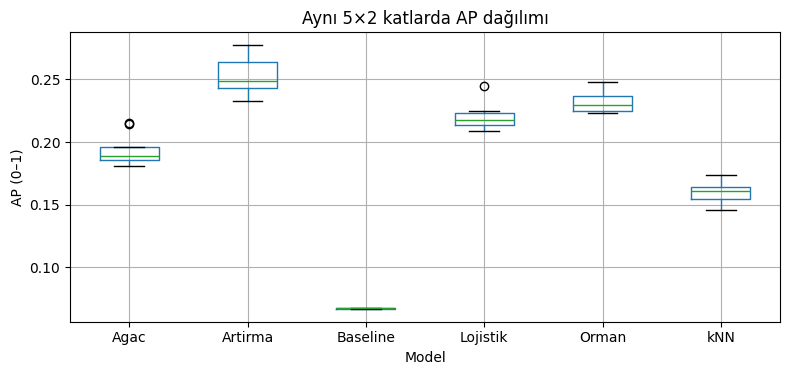

In [ ]:
modeller={
"Baseline":hat(DummyClassifier(strategy="prior")),
"Lojistik":hat(lojistik),
"Agac":hat(DecisionTreeClassifier(max_depth=6,min_samples_leaf=30,class_weight="balanced",random_state=TOHUM)),
"kNN":hat(KNeighborsClassifier(n_neighbors=21,n_jobs=1)),
"Orman":hat(RandomForestClassifier(n_estimators=100,min_samples_leaf=10,class_weight="balanced",random_state=TOHUM,n_jobs=1)),
"Artirma":hat(HistGradientBoostingClassifier(max_iter=100,max_leaf_nodes=15,random_state=TOHUM))}
for ad, model in modeller.items():
    print("Çalışıyor:",ad,flush=True)
    degerlendir(ad,model)
puanlar=pd.DataFrame(kayitlar)
model_puanlari=puanlar[puanlar.deney.isin(modeller)]
ozet=model_puanlari.groupby("deney")[list(olcutler)].agg(["mean","std"])
# mean ve standart sapma hesaplama
display(ozet)
ozet.to_csv(cikti/"model_ozeti.csv")
model_puanlari.boxplot(column="AP",by="deney",figsize=(8,4)); plt.ylabel("AP (0–1)"); plt.xlabel("Model"); plt.title("Aynı 5×2 katlarda AP dağılımı"); plt.suptitle(""); plt.tight_layout(); plt.show()


In [ ]:
sirali_cv=model_puanlari.groupby("deney").AP.mean().sort_values(ascending=False)
display(Markdown(f"**Güncel CV kararı:** {sirali_cv.index[0]} seçilir; AP={sirali_cv.iloc[0]:.6f}. İlk iki model: {', '.join(sirali_cv.index[:2])}. Bölüm 1'deki ağırlıksız lojistik politikası korundu."))


**Güncel CV kararı:** Artirma seçilir; AP=0.252247. İlk iki model: Artirma, Orman. Bölüm 1'deki ağırlıksız lojistik politikası korundu.

Model seçimi aşağıdaki güncel CV AP tablosuna dayanır. Ortalama ± örneklem standart sapması, örtüşen katların oynaklığıdır; güven aralığı veya anlamlılık testi değildir. Pozitif yakalama, kesinlik ve F1 ayrıca okunmalıdır. En yüksek AP, en iyi kalibrasyon veya 0,5 eşiğinde en yüksek F1 anlamına gelmez.


In [ ]:
olcek_kayitlari=[]
# model başarı etkilerini inceleme
for ad,karsilastirma_modeli,olcekler in [("Lojistik",lojistik,["standart","dayanikli"]),("kNN",KNeighborsClassifier(n_neighbors=21,n_jobs=1),["standart","dayanikli","yok"])]:
    for olcek in olcekler:
        if olcek=="standart":
            degerler=model_puanlari.loc[model_puanlari.deney.eq(ad),"AP"].to_numpy()
        else:
            degerler=cross_validate(hat(karsilastirma_modeli,olcekleme=olcek),egitim,sonuc,cv=katlar,scoring="average_precision",n_jobs=1,error_score="raise")["test_score"]
        for kat,deger in enumerate(degerler):olcek_kayitlari.append({"model":ad,"olcek":olcek,"kat":kat,"AP":deger})
olcek_puanlari=pd.DataFrame(olcek_kayitlari)
display(olcek_puanlari.groupby(["model","olcek"]).AP.agg(["mean","std"]))
olcek_puanlari.to_csv(cikti/"olcekleme_duyarliligi.csv",index=False)


mean       std
model    olcek                        
Lojistik dayanikli  0.219536  0.010641
         standart   0.219723  0.010474
kNN      dayanikli  0.152384  0.009089
         standart   0.159669  0.008172
         yok        0.077081  0.002684

In [ ]:
display(Markdown("**Ölçekleme kararı:** Ana modellerde standart ölçekleme korunur. Yukarıdaki güncel farklar betimseldir; yeni bağımsız model seçimi değildir."))


**Ölçekleme kararı:** Ana modellerde standart ölçekleme korunur. Yukarıdaki güncel farklar betimseldir; yeni bağımsız model seçimi değildir.

Ölçekleme duyarlılığında aynı modelin alternatifleri aynı katlarda karşılaştırılır. Dayanıklı ölçekleme otomatik olarak üstün değildir. Bu ek analiz test kümesiyle yeniden model seçmek için kullanılmaz.


**Seçimin anlamı:** Artırma'nın yüksek AP'si iyi kalibre edilmiş abonelik olasılıkları veya 0,5 eşiğinde en iyi F1 anlamına gelmez. Eşik/kalibrasyon optimizasyonu yapılmadığı için model, bu çalışmanın sıralama amacı ve sabit protokolü kapsamında seçilir. Diğer yöntemler bütün kullanımlarda reddedilmiş olarak kabul edilmez.

**Yorum:** En yüksek ortalama AP seçilir; AP eşitliğinde ise daha basit model tercih edilir. AP farkıyla F1 farkı aynı değildir: sıralama iyi olsa bile 0.5 eşiğinde az pozitif bulunabilir. Orman-ağaç ağırlıklı, boosting/kNN ağırlıksızdır; bu karşılaştırma algoritma ailesinin saf etkisi değil, belirtilen kurulumların karşılaştırmasıdır.

## 4.2.2 Ağacın alan yorumu ve optimist yanlılık
İlk iki düzeydeki koşullar birlikte okunur. One-hot eşikleri 0.5 kategori yok/var anlamındadır; sayısal eşikler standartlaştırılmış birimdedir, ekonomik sınır diye yorumlanamaz. İç içe CV'de her dış eğitim kümesinde GridSearch yeniden kurulur; dış doğrulama tuning görmez.

**Kesinlik tanımı:** Hiç pozitif tahmin yoksa kesinlik TP/(TP+FP) tanımsızdır. sklearn skorlama varsayılanıyla 0 raporlar; WEKA  da `?` ıle gösterebilir. Bu araç sözleşmesidir; modelin pozitif kesinliğinin gerçekten ölçüldüğü anlamına gelmez.


In [ ]:
modeller["Agac"].fit(egitim,sonuc)
# karar agacı egitme
isimler=modeller["Agac"].named_steps["hazirla"].get_feature_names_out()
print(export_text(modeller["Agac"].named_steps["model"],feature_names=list(isimler),max_depth=2))
ic_katlar=StratifiedKFold(3,shuffle=True,random_state=TOHUM)
aramali=GridSearchCV(modeller["Agac"],{"model__max_depth":[3,6,9],"model__min_samples_leaf":[30,100]},cv=ic_katlar,scoring="average_precision",n_jobs=1)
aramali.fit(egitim,sonuc)
ic_iyi=aramali.best_score_
dis_skor=cross_validate(aramali,egitim,sonuc,cv=katlar,scoring="average_precision",n_jobs=1,error_score="raise")["test_score"]
print("GridSearch best_score_",ic_iyi,"İç içe dış AP",dis_skor.mean(),"±",dis_skor.std(ddof=1),"fark",ic_iyi-dis_skor.mean())


|--- kategorik__ay_apr <= 0.50
|   |--- kategorik__ay_mar <= 0.50
|   |   |--- kategorik__missingindicator_iletisim_False <= 0.50
|   |   |   |--- truncated branch of depth 4
|   |   |--- kategorik__missingindicator_iletisim_False >  0.50
|   |   |   |--- truncated branch of depth 4
|   |--- kategorik__ay_mar >  0.50
|   |   |--- kategorik__egitim_tertiary <= 0.50
|   |   |   |--- truncated branch of depth 4
|   |   |--- kategorik__egitim_tertiary >  0.50
|   |   |   |--- truncated branch of depth 3
|--- kategorik__ay_apr >  0.50
|   |--- kategorik__konut_kredisi_no <= 0.50
|   |   |--- sayisal__gun <= 0.51
|   |   |   |--- truncated branch of depth 4
|   |   |--- sayisal__gun >  0.51
|   |   |   |--- truncated branch of depth 3
|   |--- kategorik__konut_kredisi_no >  0.50
|   |   |--- sayisal__onceki_gun <= 3.34
|   |   |   |--- truncated branch of depth 4
|   |   |--- sayisal__onceki_gun >  3.34
|   |   |   |--- class: 0

GridSearch best_score_ 0.193372020631798 İç içe dış AP 0.20668

In [ ]:
display(Markdown(f"**Güncel arama:** iç skor {ic_iyi:.6f}; dış AP {dis_skor.mean():.6f} ± {dis_skor.std(ddof=1):.6f}; iç−dış={ic_iyi-dis_skor.mean():+.6f}."))


**Güncel arama:** iç skor 0.193372; dış AP 0.206689 ± 0.016378; iç−dış=-0.013317.

GridSearch iç skoru bağımsız test değildir. Dış katlar aramaya katılmaz; negatif iç–dış fark mümkündür. Gösterilen ağaçtaki sayısal eşikler ölçeklenmiş birimdedir; one-hot 0,5 eşikleri kategori varlığını ayırır. Bunlar nedensel veya ekonomik karar eşikleri değildir.


In [ ]:
sirali=model_puanlari.groupby("deney").AP.mean().sort_values(ascending=False)
ilk_iki=sirali.index[:2].tolist()
tahminler={}
ileri_kayitlari=[]
for ad in ilk_iki:
    modeller[ad].fit(egitim,sonuc)
    olasilik=modeller[ad].predict_proba(gelecek)[:,1]
    tahminler[ad]=(olasilik>=.5).astype(int)
    ileri_kayitlari.append({"model":ad,"AP":average_precision_score(gelecek_sonuc,olasilik),"F1":f1_score(gelecek_sonuc,tahminler[ad]),"hata_orani":np.mean(tahminler[ad]!=gelecek_sonuc.to_numpy()),"prevalans":gelecek_sonuc.mean()})
ileri_ozet=pd.DataFrame(ileri_kayitlari).set_index("model")
display(ileri_ozet)
ileri_ozet.to_csv(cikti/"ileri_donem_ozeti.csv")
yanlis_bir=tahminler[ilk_iki[0]]!=gelecek_sonuc.to_numpy()
yanlis_iki=tahminler[ilk_iki[1]]!=gelecek_sonuc.to_numpy()
b=int((yanlis_bir & ~yanlis_iki).sum()); c=int((~yanlis_bir & yanlis_iki).sum())
p_degeri=binomtest(b,b+c,.5).pvalue if b+c else 1.
print("McNemar exact",ilk_iki,"b",b,"c",c,"p",p_degeri)
from scipy.stats import chi2
ki_kare_duzeltilmis=max(abs(b-c)-1,0)**2/(b+c) if b+c else 0.
p_yaklasik=chi2.sf(ki_kare_duzeltilmis,df=1)
print("Ders 7 süreklilik düzeltmeli ki-kare",ki_kare_duzeltilmis,"p",p_yaklasik)
en_iyi_ad=ilk_iki[0]; en_iyi=modeller[en_iyi_ad]
joblib.dump(en_iyi,cikti/"p1_model.joblib")
veri.to_csv(cikti/"p1_anlamsal_temiz_veri.csv",index=False)
pd.DataFrame({"satir":veri.index,"bolum":np.where(veri.index<sinir,"gelistirme","ileri_donem")}).to_csv(cikti/"bolme.csv",index=False)
np.savez(cikti/"cv_katlari.npz",**{f"egitim_{i}":a for i,(a,b) in enumerate(katlar)},**{f"dogrulama_{i}":b for i,(a,b) in enumerate(katlar)})

print("b: birinci model yanlis, ikinci dogru; c: birinci dogru, ikinci yanlis")
print("Birinci eksi ikinci hata orani", (b-c)/len(gelecek_sonuc))


,AP,F1,hata_orani,prevalans
model,,,,
Artirma,0.479447,0.175664,0.312396,0.315824
Orman,0.463742,0.484186,0.339047,0.315824


McNemar exact ['Artirma', 'Orman'] b 1156 c 1397 p 2.0015407631085926e-06
Ders 7 süreklilik düzeltmeli ki-kare 22.561692126909517 p 2.0350220768695725e-06
b: birinci model yanlis, ikinci dogru; c: birinci dogru, ikinci yanlis
Birinci eksi ikinci hata orani -0.026650447860223376


In [ ]:
display(Markdown(f"**Güncel McNemar:** {ilk_iki[0]} / {ilk_iki[1]}; b={b}, c={c}, p={p_degeri:.6g}. Birinci−ikinci hata farkı {(b-c)/len(gelecek_sonuc)*100:+.3f} yüzde puan. " + ("Eşit marjinal hata hipotezi reddedilir." if p_degeri<.05 else "Eşit marjinal hata hipotezi reddedilemedi; eşitlik kanıtlanmadı.")))
assert set(en_iyi.feature_names_in_)==set(egitim.columns)
# Ayrı Bölüm 3'ün güvenilen yerel Bölüm 2 çıktısıyla devam etmesi için.
joblib.dump({"modeller":modeller,"en_iyi":en_iyi,"en_iyi_ad":en_iyi_ad,"model_puanlari":model_puanlari,"puanlar":puanlar,"ilk_iki":ilk_iki,"ileri_ozet":ileri_ozet,"b":b,"c":c,"p_degeri":p_degeri,"ic_iyi":ic_iyi,"dis_skor":dis_skor},cikti/"bolum2_durum.joblib")


**Güncel McNemar:** Artirma / Orman; b=1156, c=1397, p=2.00154e-06. Birinci−ikinci hata farkı -2.665 yüzde puan. Eşit marjinal hata hipotezi reddedilir.

['uretilen/bolum2_durum.joblib']

İleri dönem sonuçları ve McNemar değerleri güncel tablodan hesaplanır. Test yalnız sınıflandırma hatalarının eşitliğini sorgular; AP/F1 farkını test etmez. Satırlar arası bağımsızlık kimlik ve tam tarih yokluğunda tam denetlenemez. Model yalnız geliştirme verisinde eğitilir; temiz CSV içindeki hedef ve süre modele verilmez.
